# Lab 0 - Introduction and Programming Quantum Computers

## A brief Introduction:

A summary of the operations of the most common gates on single-qubit states is given by the image below, where the phases are shown in degrees.

![Image]( https://drive.google.com/uc?id=1mUgr5s4TkNk0yrBNj8cj33Lrq6rQiXqu)




Let's install the needed libraries

In [1]:
%pip install qiskit qiskit-ibm-provider jupyter matplotlib qiskit_aer qiskit-ibm-runtime pylatexenc

  Using cached qiskit-2.4.2-cp310-abi3-win_amd64.whl.metadata (14 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached matplotlib-3.11.0-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached qiskit_aer-0.17.2-cp312-cp312-win_amd64.whl.metadata (8.5 kB)
  Using cached qiskit_ibm_runtime-0.47.0-py3-none-any.whl.metadata (23 kB)
  Using cached pylatexenc-2.10-py3-none-any.whl
  Using cached numpy-2.5.0-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.0-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached stevedore-5.8.0-py3-none-any.whl.metadata (2.3 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached requests_ntlm-1.3.0-py3-none-any.whl.metadata (2.4 kB)
  Using cached urllib3-2.7.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached websocket_client-1.9.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached jupyter_console-6.6.3-py3-none


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install dotenv

  Using cached python_dotenv-1.2.2-py3-none-any.whl.metadata (27 kB)
Using cached python_dotenv-1.2.2-py3-none-any.whl (22 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
from dotenv import load_dotenv
from qiskit_ibm_runtime import QiskitRuntimeService
import warnings


In [ ]:
warnings.filterwarnings("ignore")

QiskitRuntimeService.save_account(
token = os.environ.get("IBM_API_KEY"), # Use the 44-character API_KEY you created and saved from the IBM Quantum Platform Home dashboard
instance = os.environ.get("CRN"),
overwrite=True,         # Overwrites any old configuration saved on your disk
set_as_default=True,
)

# Verify
service = QiskitRuntimeService()
backends = service.backends()
print(f"Account OK. {len(backends)} backend(s) available:")
for b in backends[:5]:
    print(f"  {b.name} ({b.num_qubits} qubits)")

Account OK. 3 backend(s) available:
  ibm_fez (156 qubits)
  ibm_marrakesh (156 qubits)
  ibm_kingston (156 qubits)


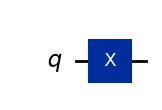

In [4]:
from qiskit import QuantumCircuit


# Create a new circuit with a single qubit
qc = QuantumCircuit(1)
# Add a Not gate to qubit 0
qc.x(0)
# Return a drawing of the circuit using MatPlotLib ("mpl"). This is the
qc.draw(output = 'mpl')
# last line of the cell, so the drawing appears in the cell output.


> For a full list of gates visit [Qiskit Documentation](https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.QuantumCircuit)

## Quantum Hello World!

Let's start by generating a two-qubit Bell State using a Qiskit Pattern. To achive this we need to follow four steps:

1. Map circuits and operators
2. Optimize the circuit
3. Execute the circuit
4. Post-process the results

###  **Step 1:** Map circuits and operators <a name="step-1"></a>


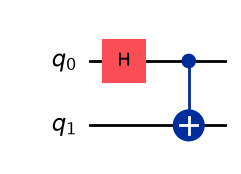

In [5]:
# Create a new circuit with two qubits
qc = QuantumCircuit(2)

# Add a Hadamard gate to qubit 0
qc.h(0)
# Perform a CNOT gate on qubit 1, controlled by qubit 0
qc.cx(0,1)

# Return a drawing of the circuit using MatPlotLib ("mpl"). This is the
# last line of the cell, so the drawing appears in the cell output.
qc.draw(output="mpl")


We want to be able to visualize that our circuit does what we expect it to do. To accomplish this, let's set up some **operators**.

Here we create some operators for our two qubits. Some (like `XX`)  measure both qubits, while others (like `XI`) only measure one. Later we will check their expectation values to make sure our circuit is working properly. Because we've created an entangled Bell state, we should expect that our operators only measuring one qubit have an expectation value of 0. Similarly, we should expect the operators which measure both qubits to come back with some non-zero (hopefully close to 1) expectation value.

How do we do this? We simply use a combination of `X`, `Z`, and Identity (`I`) operators.

* Applying an `I` gate to a qubit is the same as doing nothing to a qubit. We can use a combination of `X`/`Z` and `I` to make the operators of `XI`, `IX`, `ZI`, and `IZ`.
* We only have two two-qubit operators to make, `XX` and `ZZ`. We use a combination of `X` or `Z` gates to make each one, respectfully.

In [6]:
from qiskit.quantum_info import SparsePauliOp

# The ZZ applies a Z operator on qubit 0, and a Z operator on qubit 1
ZZ = SparsePauliOp("ZZ")
# The ZI applies a Z operator on qubit 0, and an Identity operator on qubit 1
ZI = SparsePauliOp("ZI")
# The IX applies an Identity operator on qubit 0, and an X operator on qubit 1
IX = SparsePauliOp("IX")
# Similarly we create the rest the operators
IZ = SparsePauliOp("IZ")
XX = SparsePauliOp("XX")
XI = SparsePauliOp("XI")

# We create an array of observables to study the different expectation values

observables = [IZ, IX, ZI, XI, ZZ, XX]

### **Step 2:** Optimize the circuit <a name="step-2"></a>

To optimize the circuit, we can use the Qiskit transpiler. During transpilation, we can optimally layout our qubits to minimize the required number of gates, for example. This circuit is too simple and this step doesn't make sense to this.



In [ ]:
#from qiskit_aer import AerSimulator
#from qiskit.transpiler import generate_preset_pass_manager

#pm = generate_preset_pass_manager(optimization_level=1, AerSimulator())
#isa_circuit = pm.run(qc)

### **Step 3:** Execute the circuit <a name="step-3"></a>

In [7]:
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_aer import AerSimulator

# Set up the Estimator
backend = AerSimulator()
estimator_qc = Estimator(mode = backend)
# Submit the circuit to Estimator
pub = (qc, observables)
job = estimator_qc.run ([pub])

### **Step 4:** Post-process the results <a name="step-4"></a>

Let's start by doing analysis on the expectation value from the observables

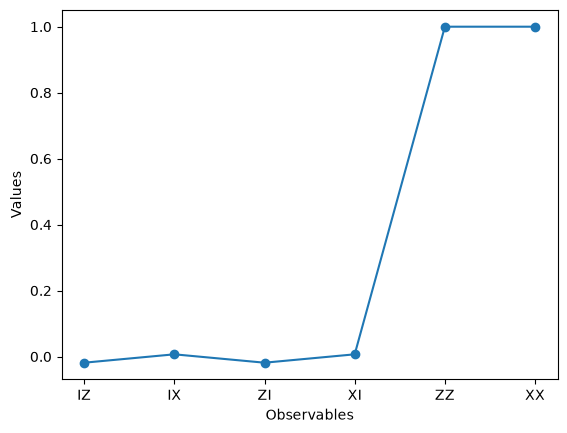

In [9]:
import matplotlib.pyplot as plt

# Collect the data
data = ['IZ', 'IX', 'ZI', 'XI', 'ZZ', 'XX']
values = job.result()[0].data.evs

# Set up our graph
container = plt.plot(data, values, '-o')

# Label each axis
plt.xlabel('Observables')
plt.ylabel('Values')

# Draw the final graph
plt.show()

Now let's get the classical register results after measurement:

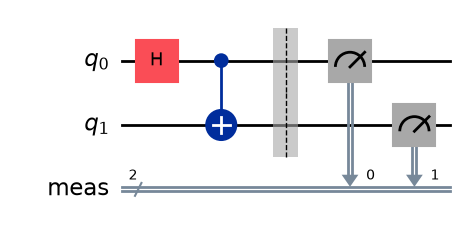

In [10]:
# Build our Quantum circuit again and add measurements at the end
qc = QuantumCircuit(2)

# Add a Hadamard gate to qubit 0
qc.h(0)
# Perform a CNOT gate on qubit 1, controlled by qubit 0
qc.cx(0,1)

# Return a drawing of the circuit using MatPlotLib ("mpl"). This is the
# last line of the cell, so the drawing appears in the cell output.
qc.measure_all()
qc.draw(output="mpl")

> The [Qiskit Sampler](https://docs.quantum.ibm.com/api/qiskit/qiskit.primitives.StatevectorSampler) primitive ([more info on Primitives here](https://docs.quantum.ibm.com/run/primitives-get-started)) returns the sampled result according to the specified output type. It allows us to efficiently sample quantum states by executing quantum circuits and providing probability distributions of the quantum states.

{'00': 510, '11': 514}


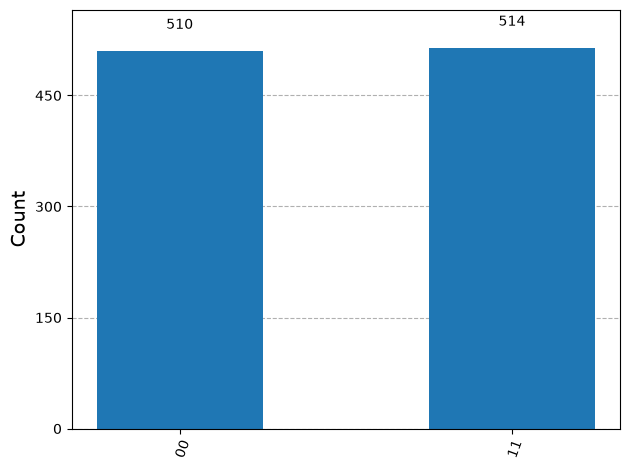

In [11]:
from qiskit.primitives import StatevectorSampler, PrimitiveJob
from qiskit.visualization import plot_histogram

sampler = StatevectorSampler()
pub = qc
job_sampler = sampler.run([pub], shots=1024)

result_sampler = job_sampler.result()
counts_sampler = result_sampler[0].data.meas.get_counts()

print(counts_sampler)
plot_histogram(counts_sampler)

{'00': 507, '11': 517}


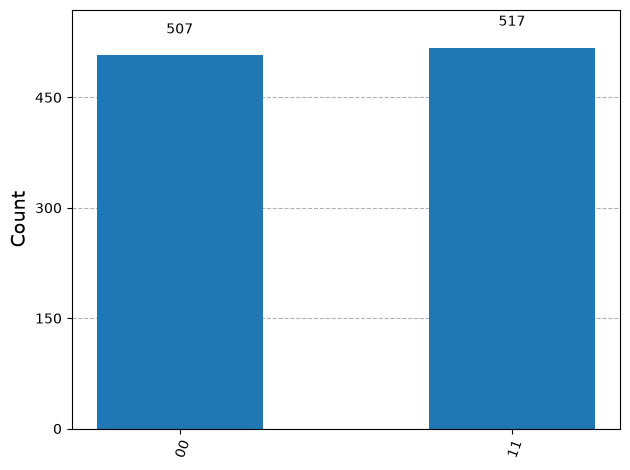

In [12]:
# Set up the Sampler
from qiskit_ibm_runtime import SamplerV2 as Sampler
backend = AerSimulator()
sampler_qc = Sampler(mode = backend)
# Submit the circuit to Sampler
pub_runtime = qc
job_runtime = sampler_qc.run ([pub_runtime], shots=1024)

result_sampler = job_runtime.result()
counts_sampler = result_sampler[0].data.meas.get_counts()

print(counts_sampler)
plot_histogram(counts_sampler)

## Let's Optimize a Circuit

Extending the Hello World to a n-qubits, we implement a [GHZ State](https://en.wikipedia.org/wiki/Greenberger%E2%80%93Horne%E2%80%93Zeilinger_state)

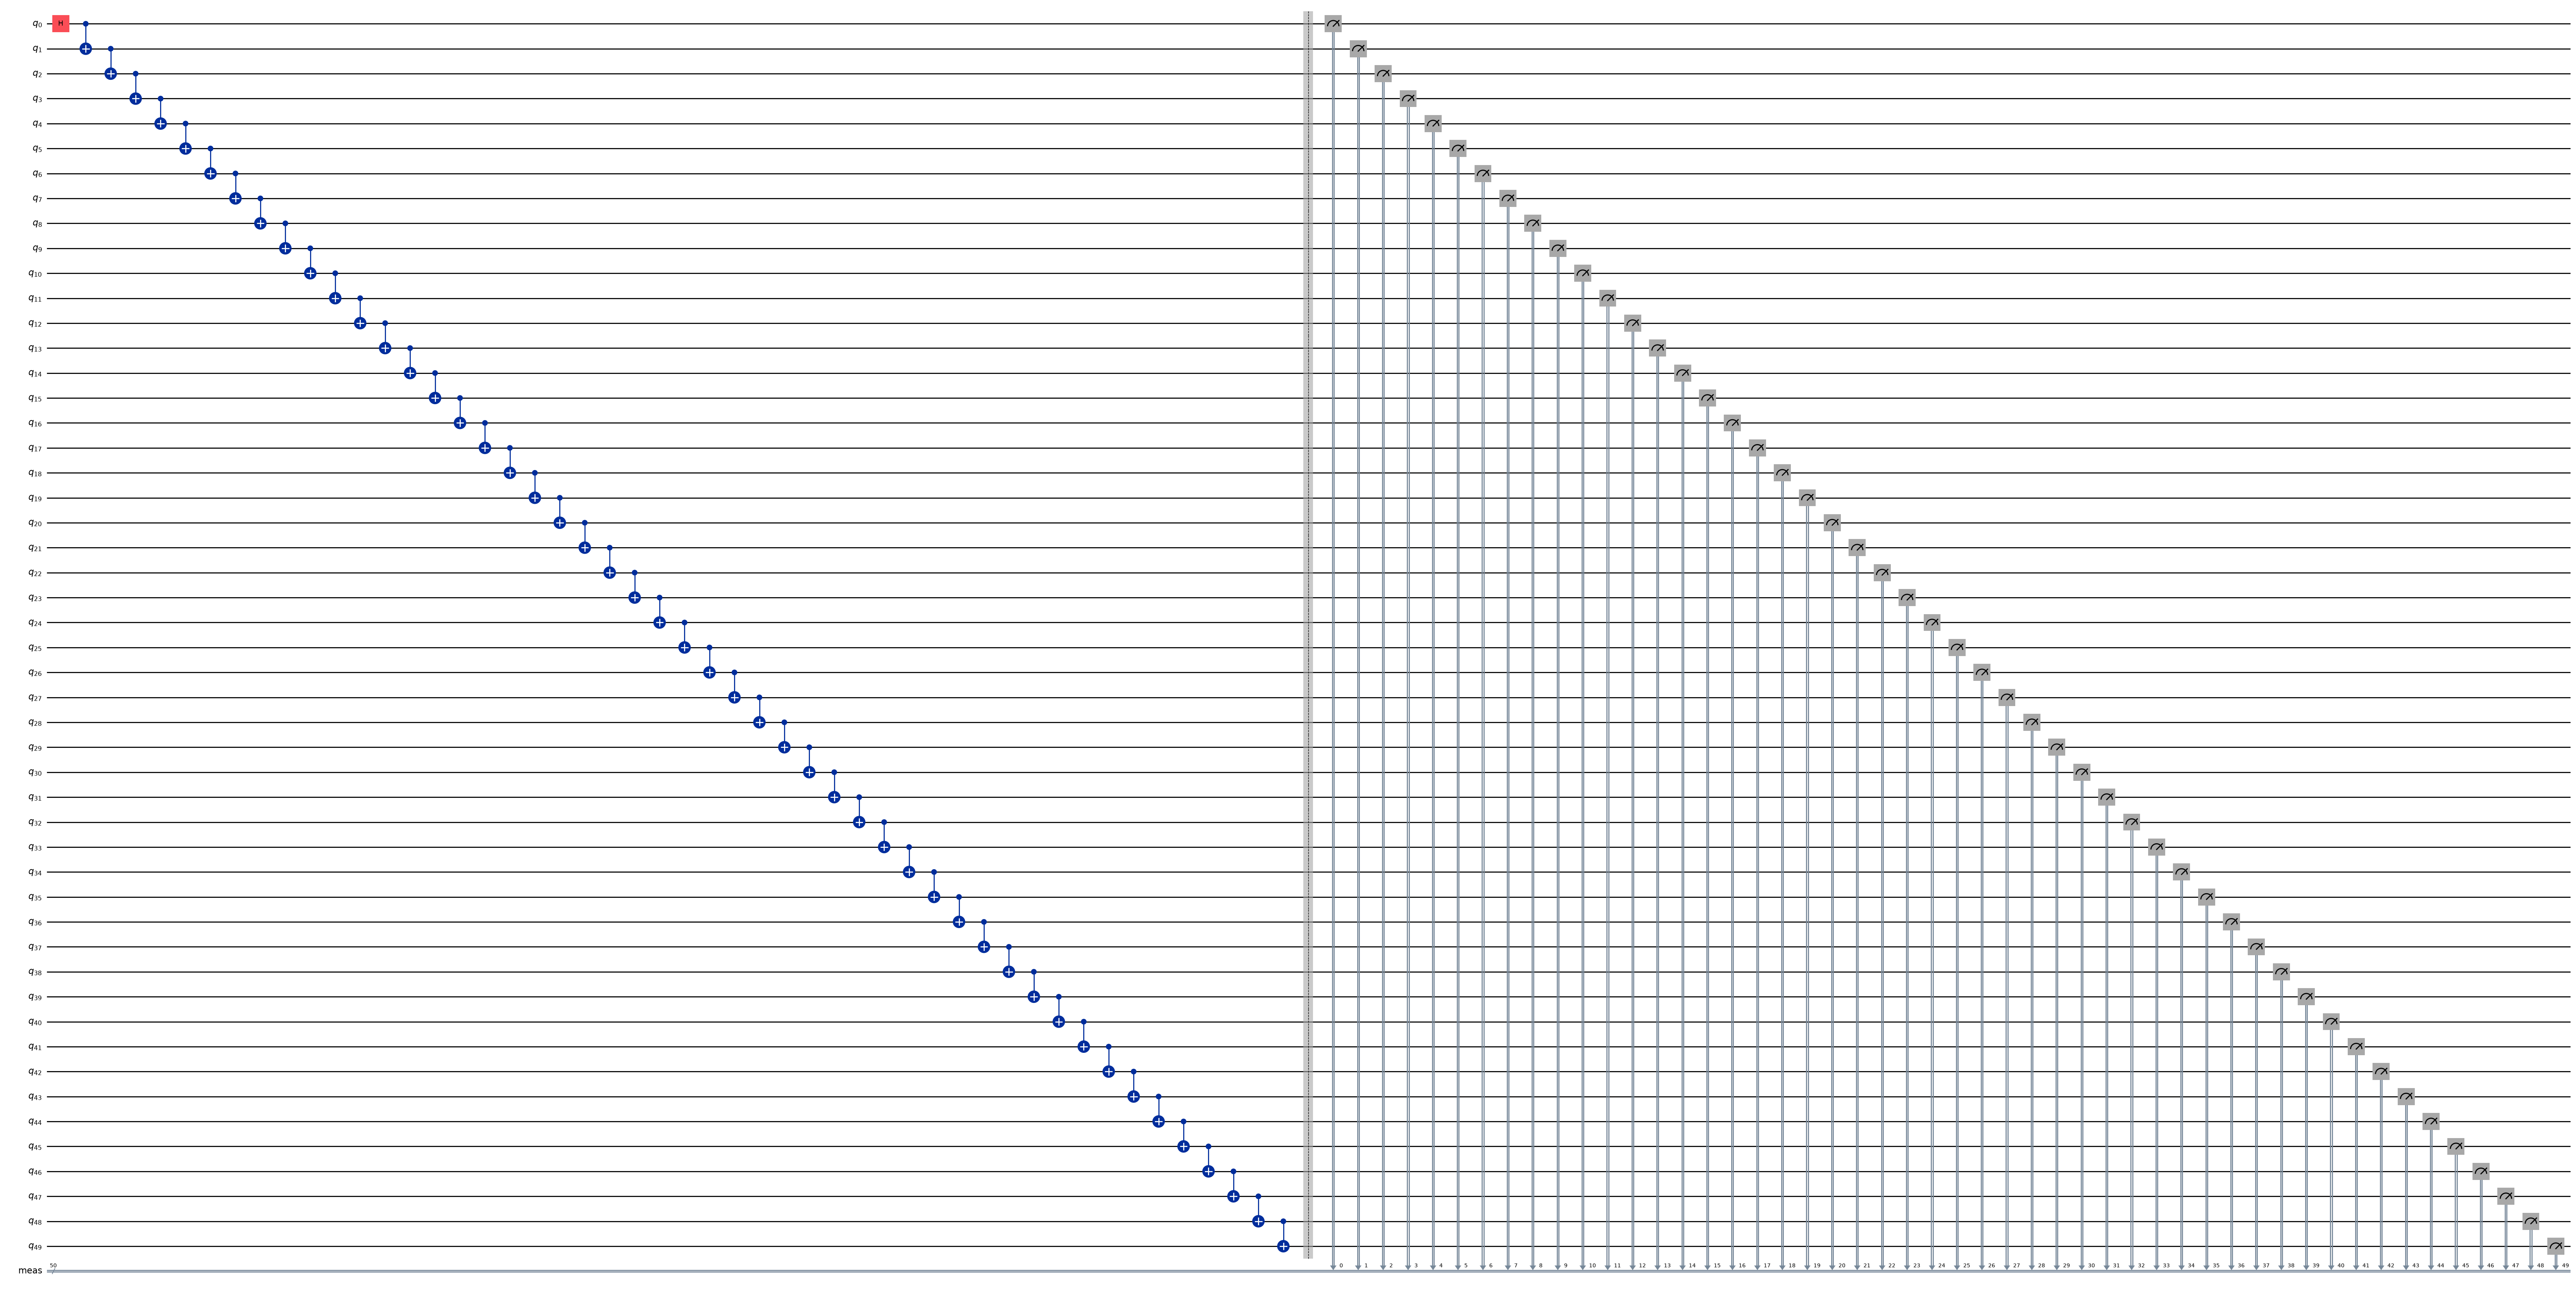

In [13]:
def get_qc_for_n_qubit_GHZ_state(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for i in range(n-1):
        qc.cx(i, i+1)
    return qc

n = 50
qc = get_qc_for_n_qubit_GHZ_state(n)
#qc.draw(output='mpl', fold=-1)

qc.measure_all()
qc.draw(output='mpl', fold=-1)

In [14]:
print(f"Linear GHZ (50 qubits): depth {qc.depth()}")

Linear GHZ (50 qubits): depth 51


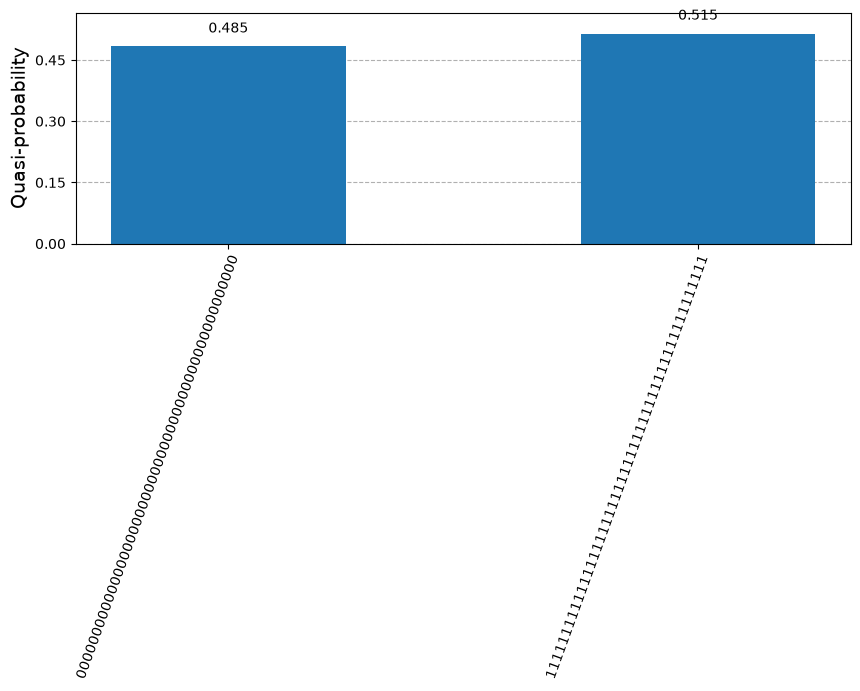

In [15]:
from qiskit_ibm_runtime import (
    QiskitRuntimeService,
    EstimatorV2 as Estimator,
    SamplerV2 as Sampler,
    EstimatorOptions
)
from qiskit.visualization import plot_circuit_layout
from qiskit.visualization import plot_gate_map, plot_circuit_layout, plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Define the backend and the pass manager
aer_sim = AerSimulator(method='matrix_product_state')
pm = generate_preset_pass_manager(backend=aer_sim, optimization_level=3)
isa_circuit = pm.run(qc)

# Define the sampler with the number of shots
sampler = Sampler(mode=aer_sim)
result = sampler.run([isa_circuit]).result()
samp_dist = result[0].data.meas.get_counts()
plot_distribution(samp_dist, figsize=(10, 3))

But now let's explore the reality of this quantum circuit when running on a "real" device:

### Without optimization:

In [16]:
service = QiskitRuntimeService()
service.backends()

[<IBMBackend('ibm_fez')>,
 <IBMBackend('ibm_marrakesh')>,
 <IBMBackend('ibm_kingston')>]

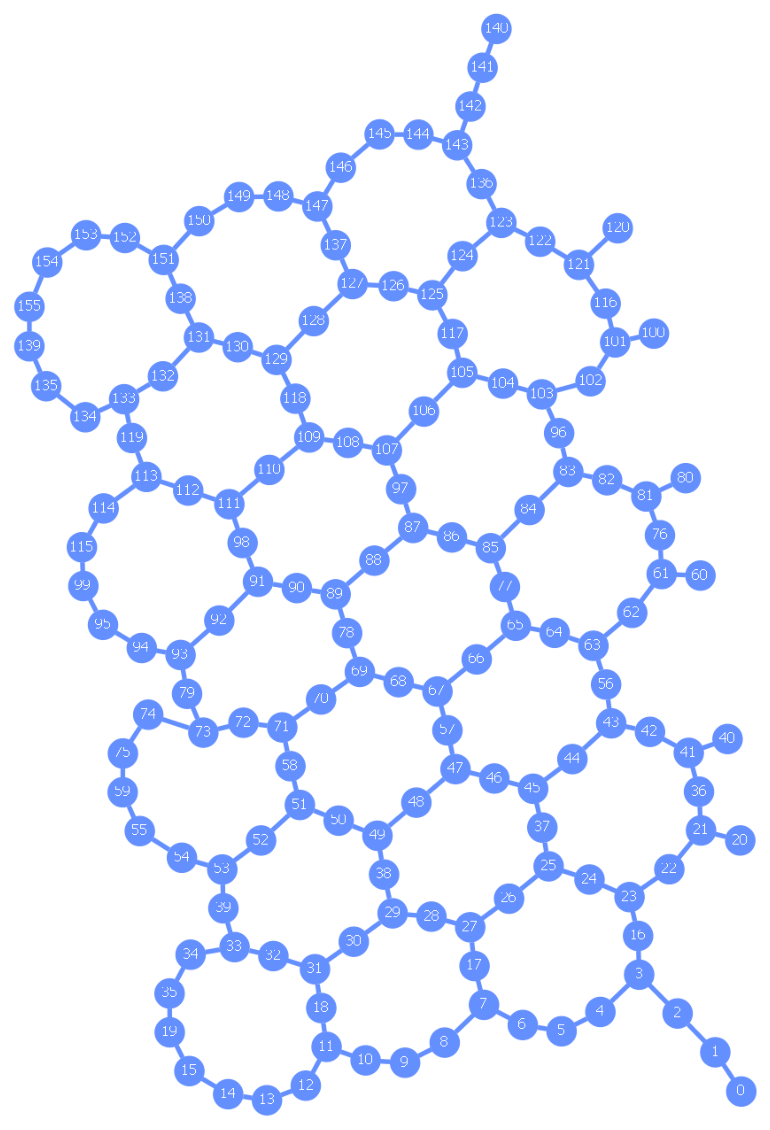

In [17]:
# Choose a real backend
backend = service.backend("ibm_marrakesh")
plot_gate_map(backend)

In [18]:
# Define a fake backend with the same properties as the real backend
fake_backend = AerSimulator.from_backend(backend)
pm = generate_preset_pass_manager(optimization_level=0, backend=fake_backend)
transpiled_qc = pm.run(qc)

print('Depth of two-qubit gates: ', transpiled_qc.depth(lambda x: len(x.qubits) == 2))
transpiled_qc.draw(output="mpl", fold=False, idle_wires=False)

Depth of two-qubit gates:  200


In [19]:
print(transpiled_qc.depth())

482


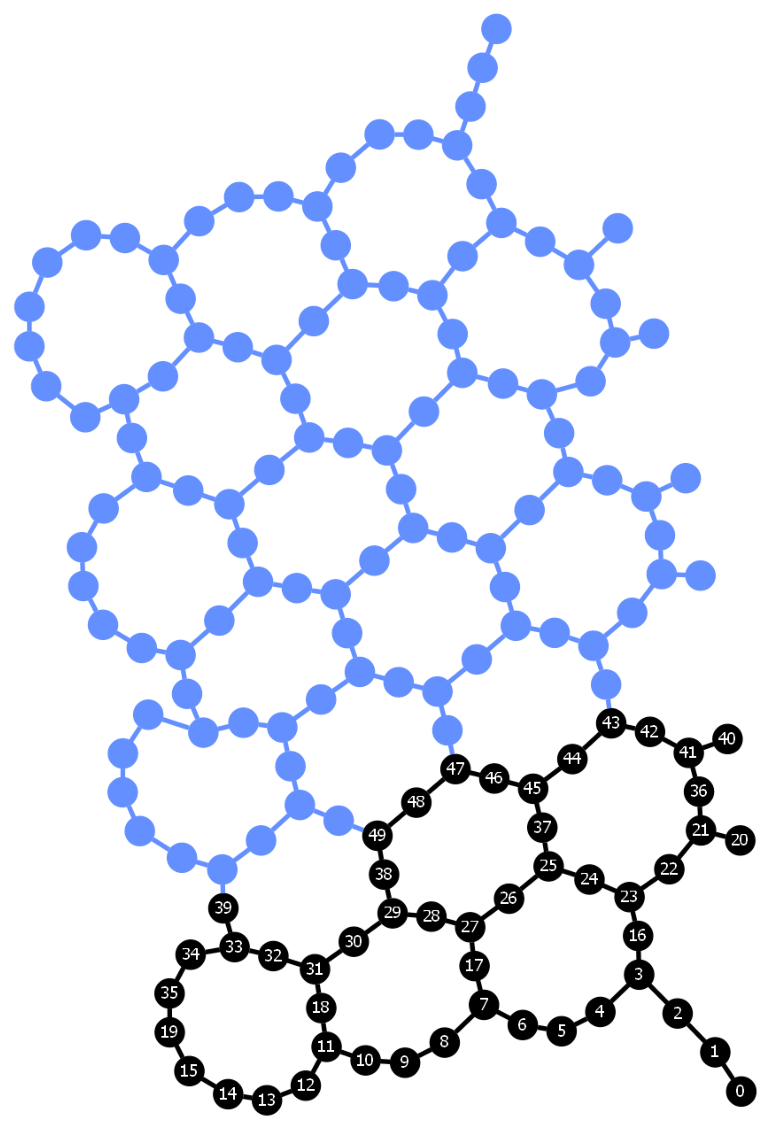

In [20]:
plot_circuit_layout(transpiled_qc, backend)

### With optimization

Depth of two-qubit gates:  49




In [21]:
# Define a fake backend with the same properties as the real backend
fake_backend = AerSimulator.from_backend(backend)
pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)
transpiled_qc = pm.run(qc)

print('Depth of two-qubit gates: ', transpiled_qc.depth(lambda x: len(x.qubits) == 2))
transpiled_qc.draw(output="mpl", fold=False, idle_wires=False)

In [22]:
print(transpiled_qc.depth())

151


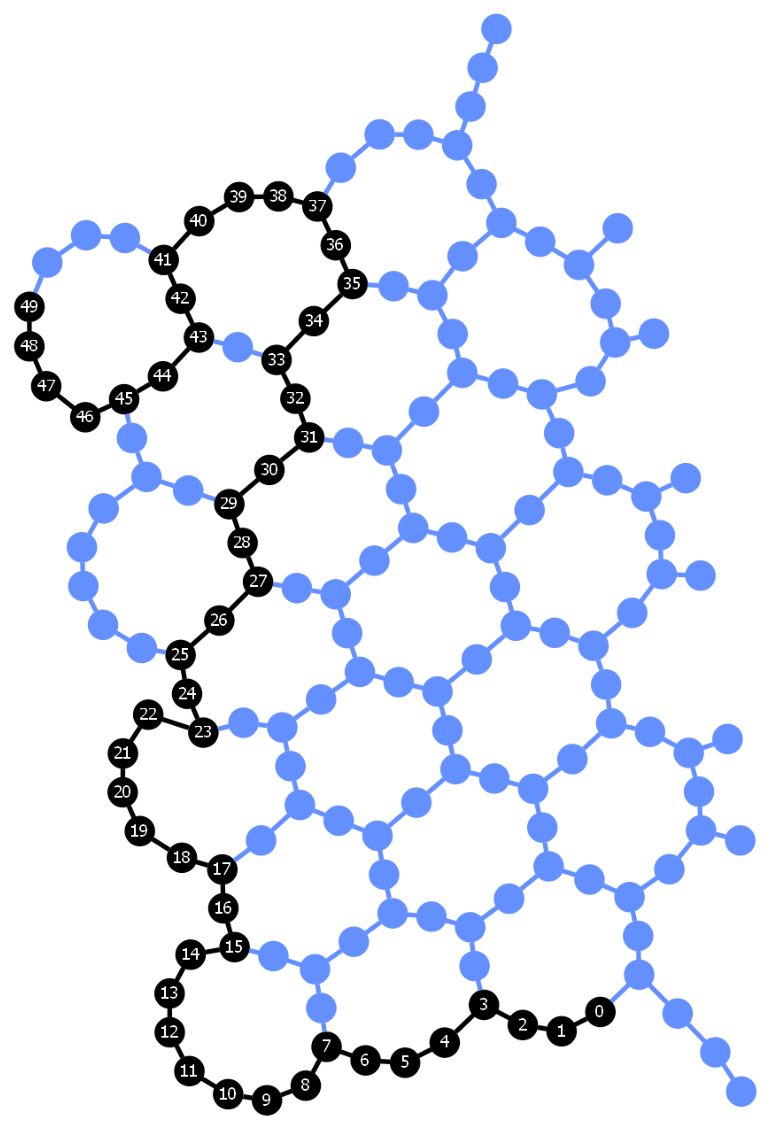

In [23]:
plot_circuit_layout(transpiled_qc, backend)

## Implementing a better approach

Now is your time to create a better version of the GHZ circuit, create an alternative with the smaller circuit depth.

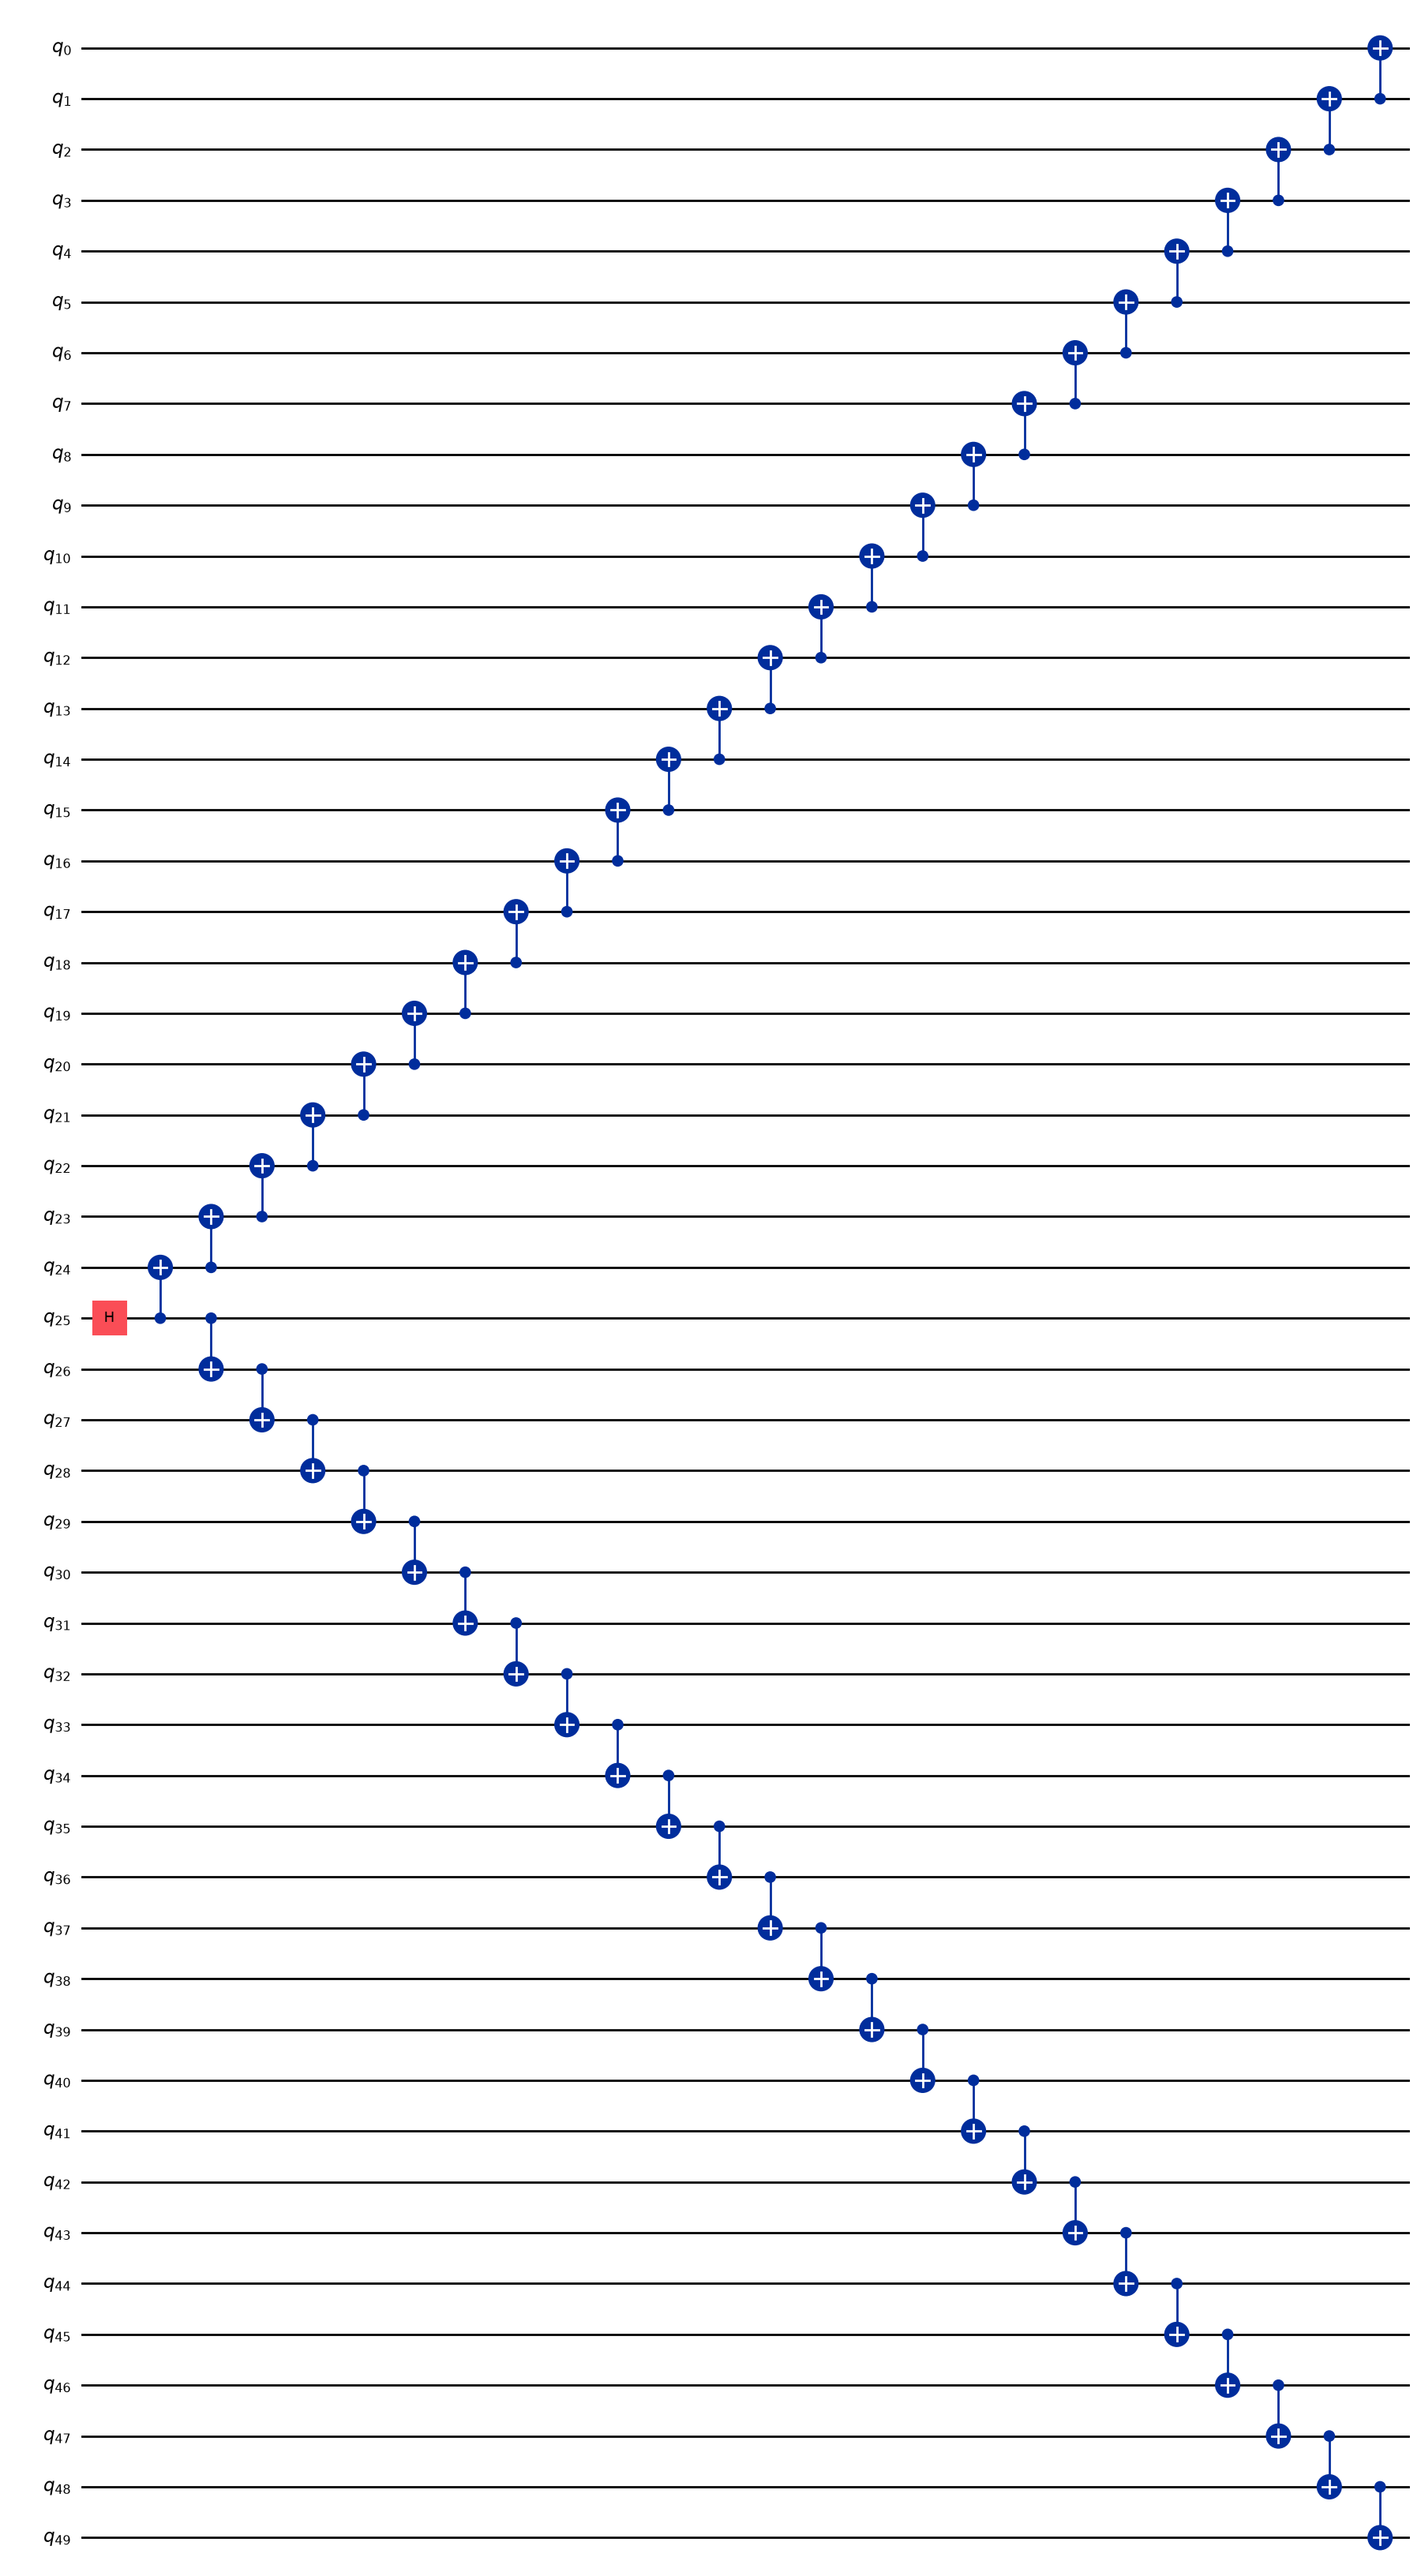

In [24]:
n = 50
num_qubits = n
def generate_GHZ(qc):
    #  Insert your code here:
    mid = n // 2
    qc.h(mid)

    # Spread left and right simultaneously
    for step in range(1, n):
        left = mid - step
        right = mid + step
        if left >= 0:
            qc.cx(left + 1, left)  # Spread left
        if right < n:
            qc.cx(right - 1, right)  # Spread right
        if left <= 0 and right >= n - 1:
            break
    return qc

qc = QuantumCircuit(num_qubits)
generate_GHZ(qc)
qc.draw(output='mpl', fold=-1)

In [25]:
print(f"Half GHZ (50 qubits): depth {qc.depth()}")

Half GHZ (50 qubits): depth 26


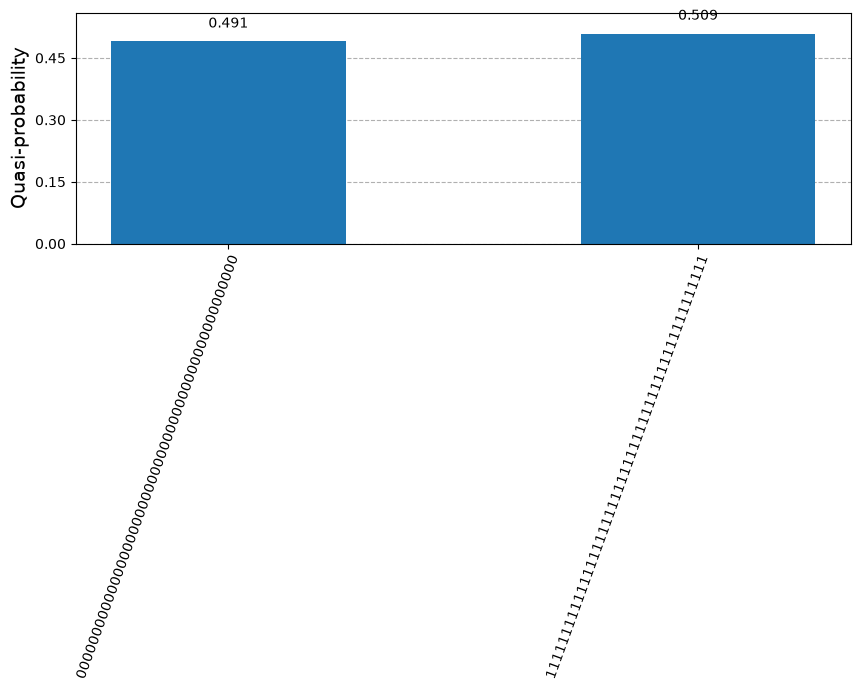

In [26]:
qc.measure_all()

# Define the backend and the pass manager
aer_sim = AerSimulator(method='matrix_product_state')
pm = generate_preset_pass_manager(backend=aer_sim, optimization_level=3)
isa_circuit = pm.run(qc)

# Define the sampler with the number of shots
sampler = Sampler(mode=aer_sim)
result = sampler.run([isa_circuit]).result()
samp_dist = result[0].data.meas.get_counts()
plot_distribution(samp_dist, figsize=(10, 3))

Depth of two-qubit gates:  25




In [27]:
# Define a fake backend with the same properties as the real backend
fake_backend = AerSimulator.from_backend(backend)
pm = generate_preset_pass_manager(optimization_level=1, backend=fake_backend)
transpiled_qc = pm.run(qc)

print('Depth of two-qubit gates: ', transpiled_qc.depth(lambda x: len(x.qubits) == 2))
transpiled_qc.draw(output="mpl", fold=False, idle_wires=False)

In [28]:
print(transpiled_qc.depth())

104


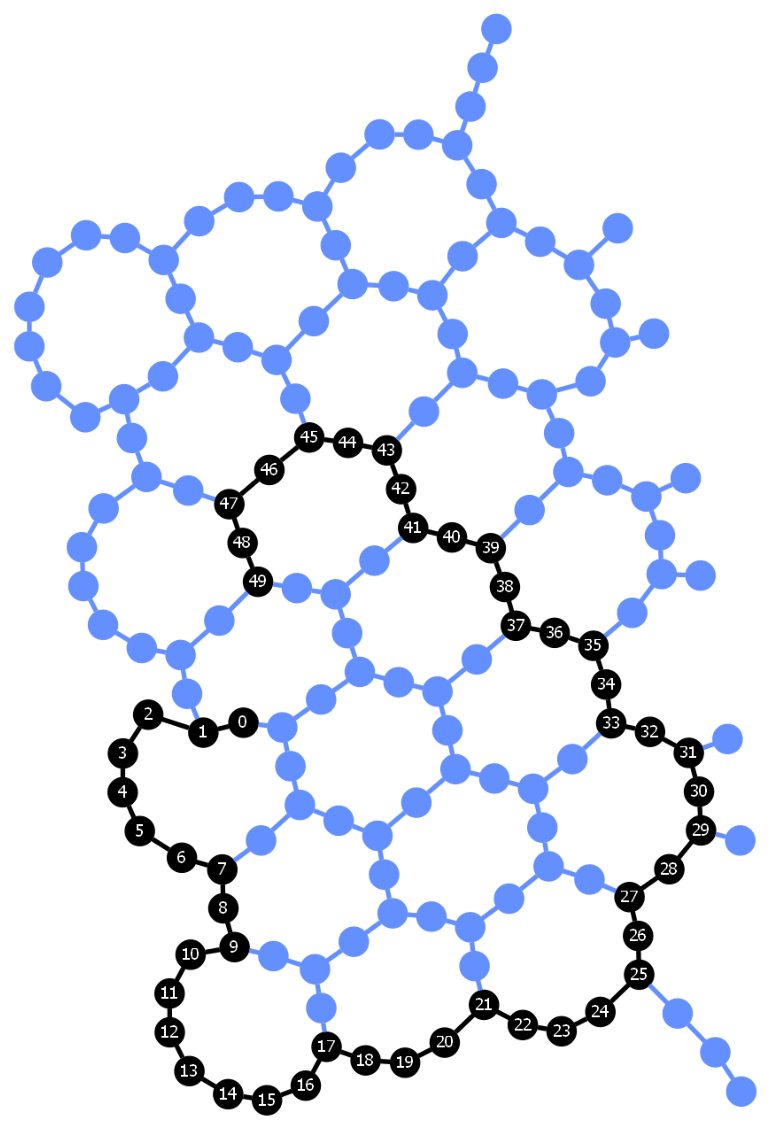

In [29]:
plot_circuit_layout(transpiled_qc, backend)

## Execute your circuit on a real backend! (OPTIONAL)

## Comparison between normal and a hardware aware GHZ circuit

In [74]:
service = QiskitRuntimeService(channel="ibm_quantum_platform")
backend = service.least_busy(simulator=False, operational=True, min_num_qubits=100)
print(f"We are using {backend.name}")

We are using ibm_kingston


In [75]:
from qiskit import transpile
#fake_backend = AerSimulator.from_backend(backend, method = 'matrix_product_state')

n = 50

# Naive: fan-out from qubit 0 (bad for hardware!)
qc_naive = QuantumCircuit(n)
qc_naive.h(0)
for i in range(1, n):
    qc_naive.cx(0, i)
qc_naive.measure_all()

# Efficient: fan from middle along the physical chain
qc_eff = QuantumCircuit(n)
mid = n // 2  # qubit 25
qc_eff.h(mid)
for step in range(1, n):
    left = mid - step
    right = mid + step
    if left >= 0:
        qc_eff.cx(left + 1, left)
    if right < n:
        qc_eff.cx(right - 1, right)
    if left <= 0 and right >= n - 1:
        break
qc_eff.measure_all()

# Full transpile to native gates (for execution)
pm = generate_preset_pass_manager(
    optimization_level=3, backend=backend, #initial_layout=list(range(n))
)
isa_naive = pm.run(qc_naive)
isa_eff = pm.run(qc_eff)

# Parallel transpile that keeps SWAPs visible (for the purposes of only counting)
isa_naive_swaps = transpile(
    qc_naive,
    coupling_map=backend.coupling_map,
    basis_gates=["h", "cx", "swap"],
    #initial_layout=list(range(n)),
    optimization_level=3,
)
isa_eff_swaps = transpile(
    qc_eff,
    coupling_map=backend.coupling_map,
    basis_gates=["h", "cx", "swap"],
    #initial_layout=list(range(n)),
    optimization_level=3,
)
naive_swaps = isa_naive_swaps.count_ops().get("swap", 0)
eff_swaps = isa_eff_swaps.count_ops().get("swap", 0)

print("=== Circuit Comparison ===")
print(
    f"Naive:     SWAPs inserted = {naive_swaps:>2},  "
    f"transpiled depth = {isa_naive.depth():>4},  "
    f"CZ gates = {isa_naive.count_ops().get('cz', 0)}"
)
print(
    f"Efficient: SWAPs inserted = {eff_swaps:>2},  "
    f"transpiled depth = {isa_eff.depth():>4},  "
    f"CZ gates = {isa_eff.count_ops().get('cz', 0)}"
)
print(f"\n(Each SWAP becomes ~3 CZ gates, which is why the naive CZ count gets increased.)")

=== Circuit Comparison ===
Naive:     SWAPs inserted = 60,  transpiled depth =  385,  CZ gates = 213
Efficient: SWAPs inserted =  0,  transpiled depth =   79,  CZ gates = 49

(Each SWAP becomes ~3 CZ gates, which is why the naive CZ count gets increased.)


In [76]:
# Execute both circuits on the real backend

sampler = Sampler(mode = backend)
job = sampler.run([isa_naive, isa_eff], shots=1024)

print(f"Job ID   : {job.job_id()}")
print(f"Status   : {job.status()}")
print("Waiting for the job to complete (this may take several minutes)...")


Job ID   : d92eu0357qjs73b7sngg
Status   : QUEUED
Waiting for the job to complete (this may take several minutes)...


In [77]:
job_id = "d92eu0357qjs73b7sngg"
job = service.job(job_id)
result = job.result()

counts_naive = result[0].data.meas.get_counts()
counts_eff = result[1].data.meas.get_counts()
print("Execution complete!")
print(f"Naive:     {sum(counts_naive.values())} shots")
print(f"Efficient: {sum(counts_eff.values())} shots")

Execution complete!
Naive:     1024 shots
Efficient: 1024 shots


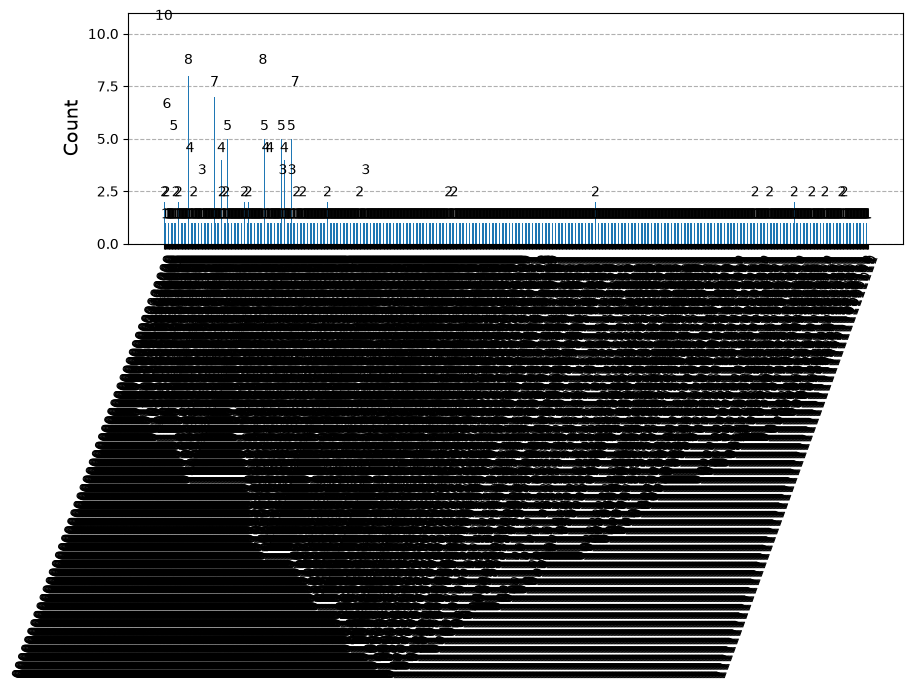

In [78]:
plot_histogram(counts_naive, figsize=(10, 3))

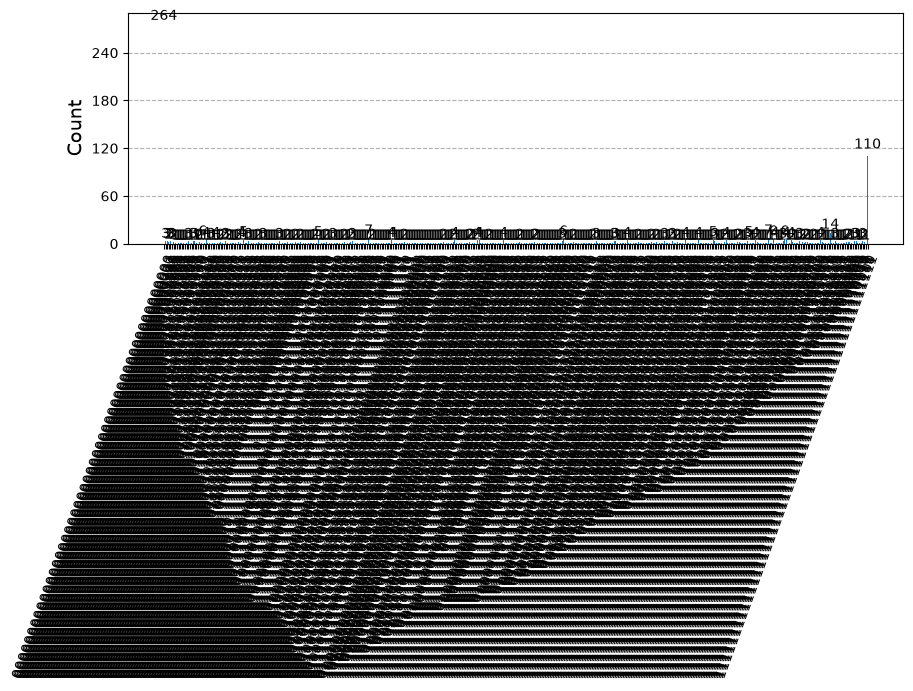

In [79]:
plot_histogram(counts_eff, figsize=(10, 3))

In [80]:
# Calculate GHZ fidelity: fraction of shots in |00...0⟩ or |11...1⟩
def ghz_fidelity(counts, n):
    total = sum(counts.values())
    correct = counts.get("0" * n, 0) + counts.get("1" * n, 0)
    return correct / total


fid_naive = ghz_fidelity(counts_naive, n)
fid_eff = ghz_fidelity(counts_eff, n)

print(f"Naive GHZ fidelity:     {fid_naive:.4f}")
print(f"Efficient GHZ fidelity: {fid_eff:.4f}")
if fid_eff > fid_naive:
    improvement = (fid_eff - fid_naive) / fid_naive * 100
    print(f"Improvement: {improvement:.1f}%")

Naive GHZ fidelity:     0.0107
Efficient GHZ fidelity: 0.3652
Improvement: 3300.0%


In [81]:
# Visualize: side-by-side histogram of measurement outcomes
fig = plot_histogram(
    [counts_naive, counts_eff],
    legend=["Naive (fan-out)", "Efficient (topology-aware)"],
    number_to_keep=8,
    sort="desc",
    title=f"{n}-Qubit GHZ: Naive vs Efficient on real backend",
    figsize=(14, 5),
)
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

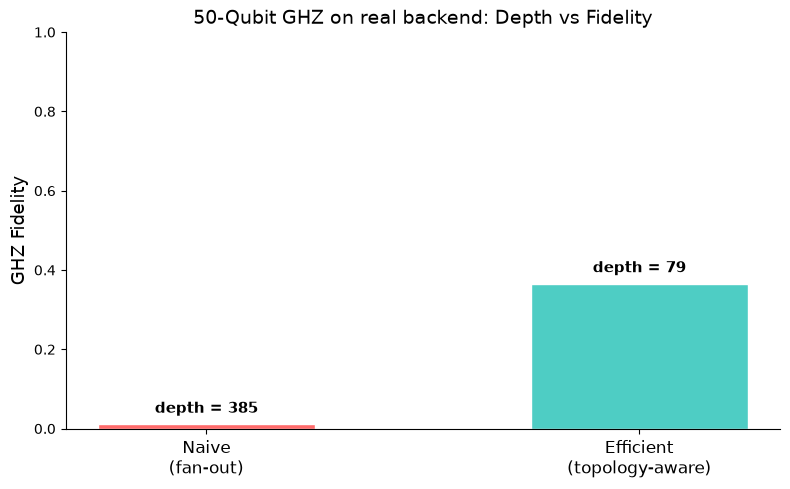

In [82]:
# Summary bar chart: fidelity vs transpiled depth
fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Naive\n(fan-out)", "Efficient\n(topology-aware)"]
fidelities = [fid_naive, fid_eff]
depths = [isa_naive.depth(), isa_eff.depth()]
colors = ["#ff6b6b", "#4ecdc4"]

bars = ax.bar(
    range(len(labels)), fidelities, color=colors, width=0.5, edgecolor="white"
)
ax.set_ylabel("GHZ Fidelity", fontsize=13)
ax.set_title(f"{n}-Qubit GHZ on real backend: Depth vs Fidelity", fontsize=14)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=12)

# Annotate bars with transpiled depth
for bar, d, f in zip(bars, depths, fidelities):
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        bar.get_height() + 0.02,
        f"depth = {d}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

ax.set_ylim(0, 1.0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

__________________________